In [ ]:
4.1: CORRELATION USING DIFFERENT KERNELS

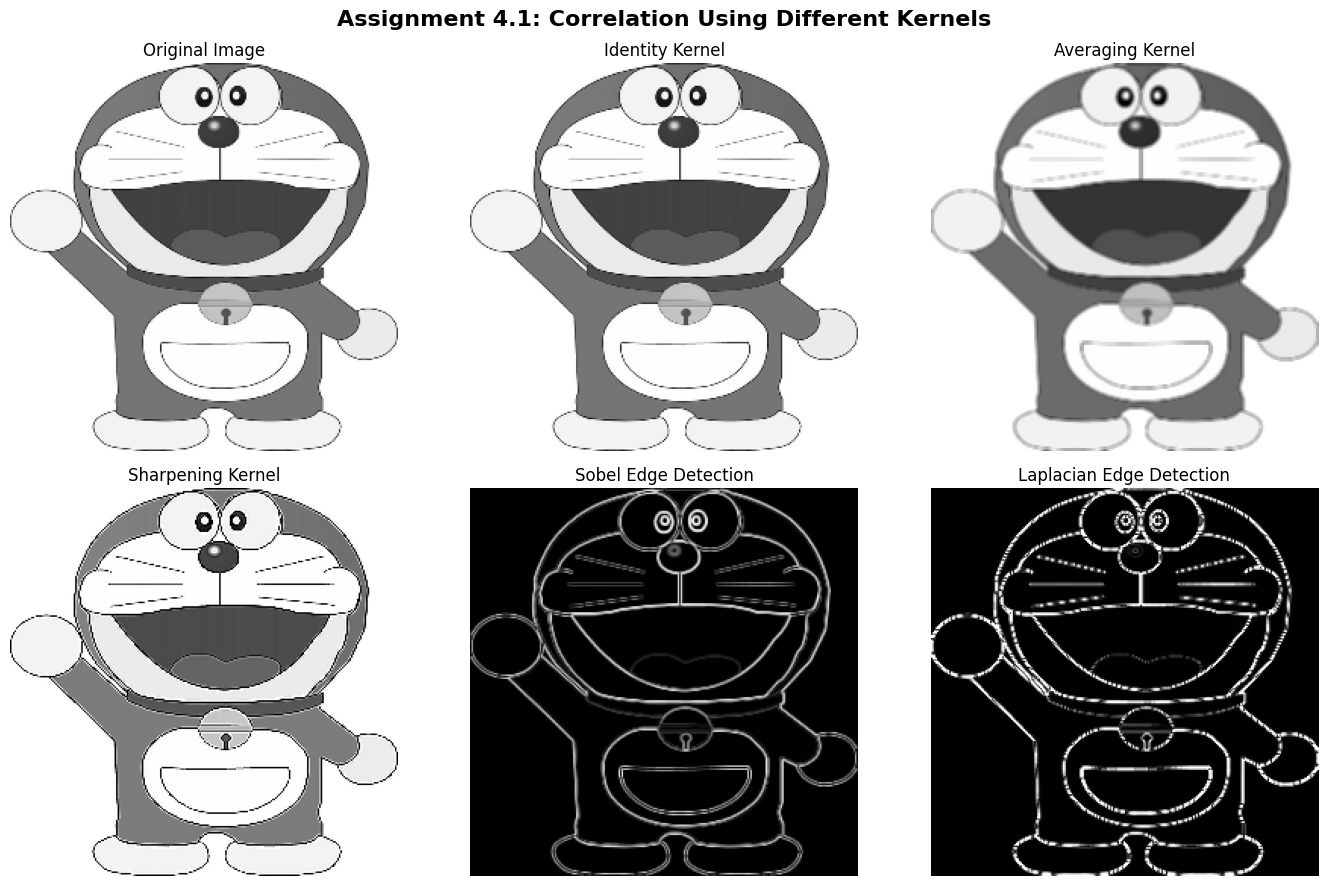

Assignment 4.1 Completed!
Image Size: (256, 256)
Total Kernels Used: 6


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# STEP 1: LOAD IMAGE
filename = "/content/image.png"

image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Image not found! Check the file name and location.")

# Resize image for clear output
image = cv2.resize(image, (256, 256))

# STEP 2: DEFINE DIFFERENT KERNELS

# Identity Kernel
identity_kernel = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
], dtype=np.float32)

# Averaging Kernel
averaging_kernel = np.ones((3, 3), dtype=np.float32) / 9

# Sharpening Kernel
sharpening_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# Sobel X Kernel
sobel_x_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

# Sobel Y Kernel
sobel_y_kernel = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

# Laplacian Kernel
laplacian_kernel = np.array([
    [ 0, -1,  0],
    [-1,  4, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# STEP 3: APPLY CORRELATION USING KERNELS

identity_result = cv2.filter2D(
    image, -1, identity_kernel
)

average_result = cv2.filter2D(
    image, -1, averaging_kernel
)

sharpen_result = cv2.filter2D(
    image, -1, sharpening_kernel
)

# Sobel Edge Detection
sobel_x = cv2.filter2D(
    image, cv2.CV_32F, sobel_x_kernel
)

sobel_y = cv2.filter2D(
    image, cv2.CV_32F, sobel_y_kernel
)

sobel_result = cv2.magnitude(sobel_x, sobel_y)

sobel_result = cv2.normalize(
    sobel_result, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Laplacian Edge Detection
laplacian_result = cv2.filter2D(
    image, cv2.CV_32F, laplacian_kernel
)

laplacian_result = cv2.convertScaleAbs(
    laplacian_result
)

# STEP 4: DISPLAY RESULTS

titles = [
    "Original Image",
    "Identity Kernel",
    "Averaging Kernel",
    "Sharpening Kernel",
    "Sobel Edge Detection",
    "Laplacian Edge Detection"
]

results = [
    image,
    identity_result,
    average_result,
    sharpen_result,
    sobel_result,
    laplacian_result
]

plt.figure(figsize=(14, 9))

for i in range(len(results)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(results[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.suptitle(
    "Assignment 4.1: Correlation Using Different Kernels",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# STEP 5: SAVE OUTPUT
plt.savefig(
    "Assignment_4_1_Correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# STEP 6: COMPLETION MESSAGE
print("Assignment 4.1 Completed!")
print("Image Size:", image.shape)
print("Total Kernels Used: 6")